# 1. Persiapan Lingkungan dan Dataset

In [ ]:
import torch
import pandas as pd
import random
import numpy as np
import torch.nn as nn
import matplotlib.pyplot as plt
import json
import shutil
from pathlib import Path
from sklearn.model_selection import train_test_split
from PIL import Image, ImageOps
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [1]:
DATA_DIR = Path(
    "/kaggle/input/competitions/"
    "document-image-classification-sd234504"
)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print("=== DATASET CHECK ===")
print("Train:", len(train_df))
print("Test :", len(test_df))
print("Classes:", train_df["label"].nunique())

print("\n=== GPU CHECK ===")
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n=== BASELINE CHECKPOINT ===")
checkpoints = list(
    Path("/kaggle/input").rglob("best_efficientnet_b0.pth")
)

for path in checkpoints:
    print("Found:", path)

print("\nCheck complete!")

=== DATASET CHECK ===
Train: 32003
Test : 7994
Classes: 16

=== GPU CHECK ===
CUDA Available: True
GPU: Tesla T4

=== BASELINE CHECKPOINT ===
Found: /kaggle/input/notebooks/aqilaikhza/02-modelling-document-classification/checkpoint/best_efficientnet_b0.pth

Check complete!


## 2. Persiapan Data dan Pembagian Terstratifikasi

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Satu gambar rusak yang ditemukan pada baseline
CORRUPTED_FILE = (
    "train/scientific_publication/"
    "2500126531_2500126536.tif"
)

# Hapus gambar rusak dari metadata
clean_df = train_df[
    train_df["filename"] != CORRUPTED_FILE
].copy().reset_index(drop=True)

# Pembagian training dan validation
train_data, val_data = train_test_split(
    clean_df,
    test_size=0.20,
    stratify=clean_df["label"],
    random_state=SEED
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

print("=== DATA PREPARATION ===")
print("Original data :", len(train_df))
print("Clean data    :", len(clean_df))
print("Training      :", len(train_data))
print("Validation    :", len(val_data))
print("Total classes :", clean_df["label"].nunique())

assert len(clean_df) == 32002
assert len(train_data) == 25601
assert len(val_data) == 6401

assert set(train_data["id"]).isdisjoint(
    set(val_data["id"])
)

print("\nData splitting successful!")

=== DATA PREPARATION ===
Original data : 32003
Clean data    : 32002
Training      : 25601
Validation    : 6401
Total classes : 16

Data splitting successful!


## 3. Preprocessing Gambar dan DataLoader

In [3]:
IMG_SIZE = 224
BATCH_SIZE = 16

class ResizeWithPadding:
    """Resize gambar tanpa mengubah rasio aspek."""

    def __init__(self, size):
        """Inisialisasi ukuran gambar output."""
        self.size = size

    def __call__(self, image):
        """Resize dan tambahkan padding putih."""
        image = image.convert("RGB")

        resized = ImageOps.contain(
            image,
            (self.size, self.size),
            method=Image.Resampling.BILINEAR
        )

        canvas = Image.new(
            "RGB",
            (self.size, self.size),
            (255, 255, 255)
        )

        x = (self.size - resized.width) // 2
        y = (self.size - resized.height) // 2

        canvas.paste(resized, (x, y))

        return canvas

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    ResizeWithPadding(IMG_SIZE),
    transforms.RandomRotation(
        degrees=3,
        fill=(255, 255, 255)
    ),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

val_transform = transforms.Compose([
    ResizeWithPadding(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

class DocumentDataset(Dataset):
    """Dataset TIFF untuk klasifikasi dokumen."""

    def __init__(self, dataframe, transform):
        """Simpan metadata dan transformasi."""
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        """Kembalikan jumlah data."""
        return len(self.df)

    def __getitem__(self, idx):
        """Muat gambar TIFF beserta label."""
        row = self.df.iloc[idx]

        image_path = (
            DATA_DIR / "train" / row["filename"]
        )

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        image = self.transform(image)
        label = int(row["label"])

        return image, label

train_dataset = DocumentDataset(
    train_data, train_transform
)

val_dataset = DocumentDataset(
    val_data, val_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Uji satu batch sebelum training
images, labels = next(iter(train_loader))

print("=== DATALOADER CHECK ===")
print("Training samples  :", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Image batch shape :", images.shape)
print("Label batch shape :", labels.shape)

assert images.shape[1:] == (3, IMG_SIZE, IMG_SIZE)

print("\nDataLoader ready!")

=== DATALOADER CHECK ===
Training samples  : 25601
Validation samples: 6401
Image batch shape : torch.Size([16, 3, 224, 224])
Label batch shape : torch.Size([16])

DataLoader ready!


## 4. Arsitektur Model ConvNeXt-Tiny

### 4.1 Inisialisasi Model ConvNeXt-Tiny

In [4]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU tidak terdeteksi!")

# Jumlah kelas dataset
NUM_CLASSES = 16

# Menggunakan bobot pretrained ImageNet
weights = ConvNeXt_Tiny_Weights.DEFAULT

# Inisialisasi arsitektur ConvNeXt-Tiny
model = convnext_tiny(weights=weights)

# Mengganti classifier agar menghasilkan 16 kelas
in_features = model.classifier[2].in_features

model.classifier[2] = nn.Linear(
    in_features,
    NUM_CLASSES
)

# Memindahkan model ke GPU
model = model.to(device)

# Menghitung total parameter
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("=" * 55)
print("CONVNEXT-TINY MODEL INFORMATION")
print("=" * 55)

print("Architecture       : ConvNeXt-Tiny")
print("Pretrained weights : ImageNet")
print("Number of classes  :", NUM_CLASSES)
print("Input image size   :", IMG_SIZE)
print("Device             :", device)

print("\nTotal parameters   :", f"{total_params:,}")
print("Trainable params   :", f"{trainable_params:,}")

# ============================================================
# MODEL FORWARD PASS TEST
# ============================================================

model.eval()

with torch.inference_mode():
    dummy_input = torch.randn(
        1,
        3,
        IMG_SIZE,
        IMG_SIZE,
        device=device
    )

    output = model(dummy_input)

print("\n=== MODEL FORWARD PASS CHECK ===")
print("Input shape :", dummy_input.shape)
print("Output shape:", output.shape)

assert output.shape == (1, NUM_CLASSES)

# Kembalikan model ke training mode
model.train()

del dummy_input, output

print("\nConvNeXt-Tiny initialized successfully!")

Device: cuda
GPU: Tesla T4
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 217MB/s]


CONVNEXT-TINY MODEL INFORMATION
Architecture       : ConvNeXt-Tiny
Pretrained weights : ImageNet
Number of classes  : 16
Input image size   : 224
Device             : cuda

Total parameters   : 27,832,432
Trainable params   : 27,832,432

=== MODEL FORWARD PASS CHECK ===
Input shape : torch.Size([1, 3, 224, 224])
Output shape: torch.Size([1, 16])

ConvNeXt-Tiny initialized successfully!


## 5. Pelatihan dan Optimasi Model Resolusi 224 × 224

### 5.1 Konfigurasi Pelatihan

In [5]:
# Pastikan variabel dari cell sebelumnya tersedia
assert "model" in globals()
assert "train_loader" in globals()
assert "val_loader" in globals()
assert "device" in globals()
assert device.type == "cuda", "Aktifkan GPU Kaggle dahulu."

# Folder output eksperimen kedua
SAVE_DIR = Path("/kaggle/working/convnext_experiment")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = SAVE_DIR / "best_convnext_tiny.pth"
HISTORY_PATH = SAVE_DIR / "training_history.csv"

EPOCHS = 10
LEARNING_RATE = 3e-5
WEIGHT_DECAY = 1e-4
PATIENCE = 3

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

# Mixed precision compatible dengan GPU T4
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)

best_val_acc = 0.0
best_epoch = 0
epochs_without_improvement = 0
history = []

print("=== TRAINING CONFIGURATION ===")
print("Model        : ConvNeXt-Tiny")
print("Device       :", device)
print("Epochs       :", EPOCHS)
print("Batch size   :", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Optimizer    : AdamW")
print("Checkpoint   :", BEST_MODEL_PATH)
print("\nTraining configuration ready!")

=== TRAINING CONFIGURATION ===
Model        : ConvNeXt-Tiny
Device       : cuda
Epochs       : 10
Batch size   : 16
Learning rate: 3e-05
Optimizer    : AdamW
Checkpoint   : /kaggle/working/convnext_experiment/best_convnext_tiny.pth

Training configuration ready!


### 5.2 Pelatihan dan Validasi

In [6]:
# CONVNEXT-TINY TRAINING LOOP

for epoch in range(EPOCHS):

    # ---------------- TRAIN ----------------
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} - Train"
    )

    for images, labels in progress:
        images = images.to(
            device, non_blocking=True
        )
        labels = labels.to(
            device, non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        train_loss += loss.item() * batch_size
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += batch_size

        progress.set_postfix(
            loss=f"{train_loss/train_total:.4f}",
            acc=f"{100*train_correct/train_total:.2f}%"
        )

    # --------------- VALIDATION ---------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for images, labels in tqdm(
            val_loader,
            desc=f"Epoch {epoch+1}/{EPOCHS} - Val"
        ):
            images = images.to(
                device, non_blocking=True
            )
            labels = labels.to(
                device, non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            val_loss += loss.item() * batch_size
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += batch_size

    train_loss /= train_total
    val_loss /= val_total

    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total

    # Rekam hasil
    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "learning_rate": optimizer.param_groups[0]["lr"]
    })

    pd.DataFrame(history).to_csv(
        HISTORY_PATH, index=False
    )

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Acc : {train_acc:.2f}%")
    print(f"Val Loss  : {val_loss:.4f}")
    print(f"Val Acc   : {val_acc:.2f}%")

    # Simpan model terbaik
    if val_acc > best_val_acc + 0.001:

        best_val_acc = val_acc
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        print("NEW BEST MODEL SAVED!")

    else:
        epochs_without_improvement += 1

    scheduler.step()

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\n" + "=" * 50)
print("TRAINING COMPLETED")
print("=" * 50)
print("Best epoch   :", best_epoch)
print("Best val acc :", f"{best_val_acc:.2f}%")
print("Checkpoint   :", BEST_MODEL_PATH)

print("\nBaseline val acc: 83.25%")
print(
    "Improvement:",
    f"{best_val_acc - 83.25:+.2f} percentage points"
)

Epoch 1/10 - Train:   0%|          | 0/1601 [00:00<?, ?it/s]

Epoch 1/10 - Val:   0%|          | 0/401 [00:00<?, ?it/s]


Epoch 1/10
Train Loss: 1.1646
Train Acc : 65.90%
Val Loss  : 0.7472
Val Acc   : 77.22%
NEW BEST MODEL SAVED!


Epoch 2/10 - Train:   0%|          | 0/1601 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c7d01c6d8a0>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    <function _MultiProcessingDataLoaderIter.__del__ at 0x7c7d01c6d8a0>self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Traceback (most recent call last):
    if w.is_alive():
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
AssertionError    if w.is_alive():: 
can only test a child process  File "/usr/lib/p

Epoch 2/10 - Val:   0%|          | 0/401 [00:00<?, ?it/s]

... (27 outputs left out)


Epoch 9/10
Train Loss: 0.0979
Train Acc : 97.16%
Val Loss  : 0.6210
Val Acc   : 86.31%
NEW BEST MODEL SAVED!


Epoch 10/10 - Train:   0%|          | 0/1601 [00:00<?, ?it/s]

Epoch 10/10 - Val:   0%|          | 0/401 [00:00<?, ?it/s]


Epoch 10/10
Train Loss: 0.0900
Train Acc : 97.45%
Val Loss  : 0.6197
Val Acc   : 86.49%
NEW BEST MODEL SAVED!

TRAINING COMPLETED
Best epoch   : 10
Best val acc : 86.49%
Checkpoint   : /kaggle/working/convnext_experiment/best_convnext_tiny.pth

Baseline val acc: 83.25%
Improvement: +3.24 percentage points


## 6. Evaluasi Model Resolusi 224 × 224

### 6.1 Evaluasi Checkpoint Terbaik

Evaluating Best ConvNeXt:   0%|          | 0/401 [00:00<?, ?it/s]

CONVNEXT-TINY FINAL EVALUATION
Validation Accuracy : 86.4865%
Macro F1-Score      : 0.8641
Baseline Accuracy   : 83.25%

=== CLASSIFICATION REPORT ===
                        precision  recall  f1-score    support
advertisement              0.8732  0.9080    0.8902   402.0000
budget                     0.7914  0.8229    0.8068   401.0000
email                      0.9803  0.9876    0.9839   403.0000
file_folder                0.9000  0.9556    0.9269   405.0000
form                       0.7119  0.7581    0.7343   401.0000
handwritten                0.9454  0.9407    0.9431   405.0000
invoice                    0.8813  0.8813    0.8813   396.0000
letter                     0.8438  0.8909    0.8667   394.0000
memo                       0.8892  0.8847    0.8869   399.0000
news_article               0.8895  0.8173    0.8519   394.0000
presentation               0.7429  0.7839    0.7628   398.0000
questionnaire              0.8540  0.7949    0.8234   390.0000
resume                     0.9

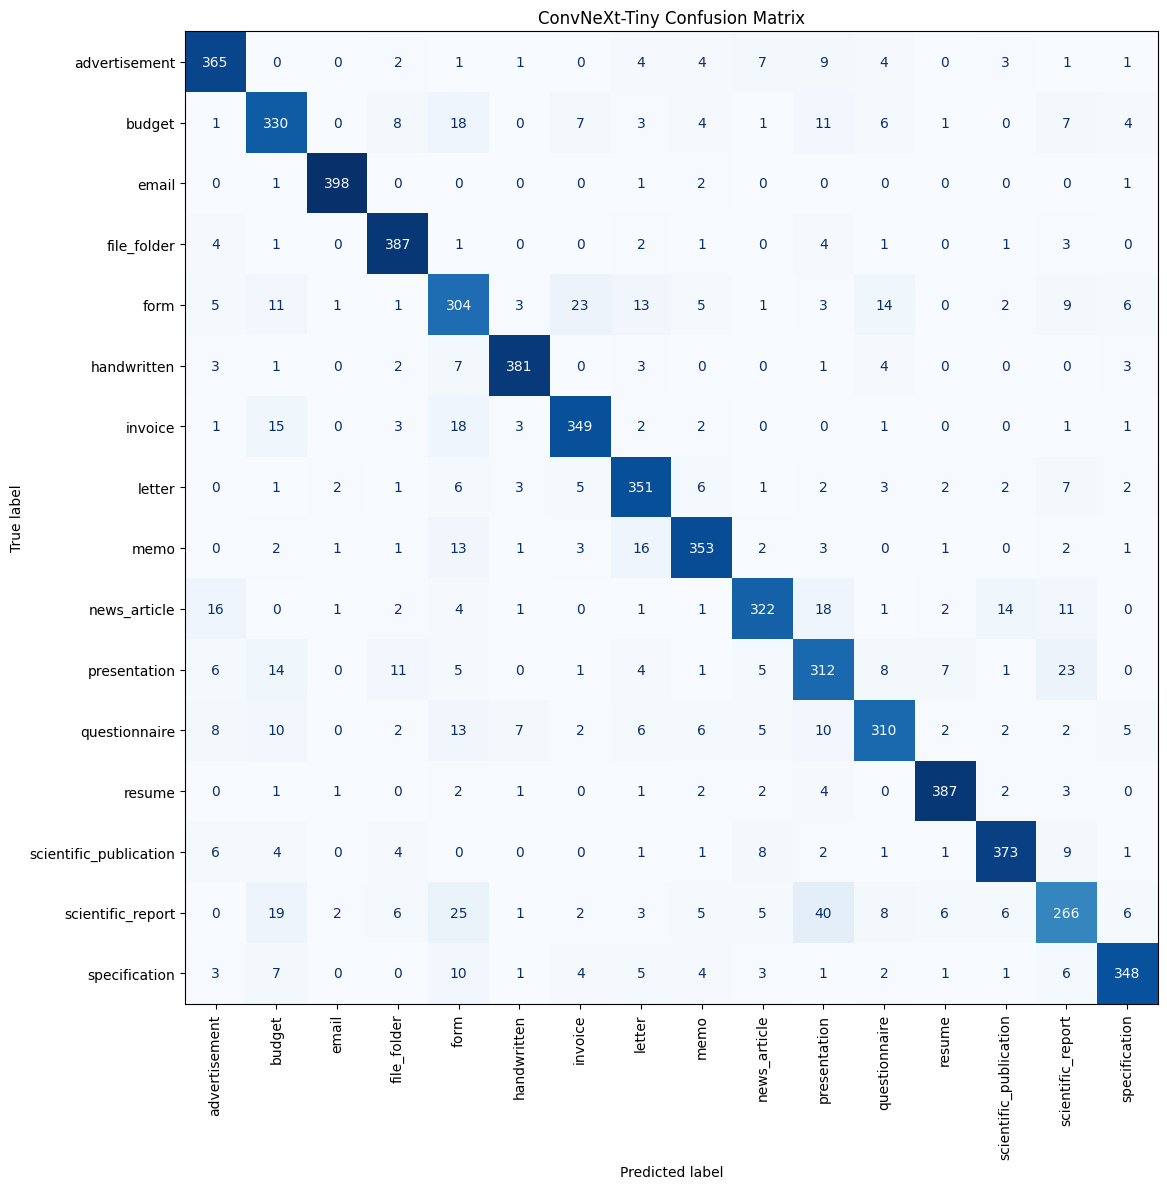


Evaluation files saved!


In [7]:
# Hindari pesan multiprocessing DataLoader
eval_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Muat checkpoint terbaik (epoch 9)
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)

model.eval()

y_true = []
y_pred = []

with torch.inference_mode():
    for images, labels in tqdm(
        eval_loader,
        desc="Evaluating Best ConvNeXt"
    ):
        images = images.to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

# Hitung metrik evaluasi
accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred, average="macro"
)

print("=" * 50)
print("CONVNEXT-TINY FINAL EVALUATION")
print("=" * 50)

print(f"Validation Accuracy : {accuracy:.4%}")
print(f"Macro F1-Score      : {macro_f1:.4f}")
print(f"Baseline Accuracy   : {83.25:.2f}%")

# Gunakan urutan nama kelas dari metadata
class_mapping = (
    clean_df[["label", "class_name"]]
    .drop_duplicates()
    .sort_values("label")
)

class_names = class_mapping["class_name"].tolist()

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(16)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T
report_df.to_csv(
    SAVE_DIR / "classification_report.csv"
)

print("\n=== CLASSIFICATION REPORT ===")
print(report_df.round(4).to_string())

# Confusion matrix
cm = confusion_matrix(
    y_true, y_pred, labels=list(range(16))
)

fig, ax = plt.subplots(figsize=(15, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False
)

plt.title("ConvNeXt-Tiny Confusion Matrix")
plt.tight_layout()

plt.savefig(
    SAVE_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nEvaluation files saved!")

## 7. Penyimpanan Checkpoint Resolusi 224 × 224

### 7.1 Verifikasi Checkpoint Terbaik

In [8]:
# Lokasi checkpoint terbaik
source = Path(
    "/kaggle/working/convnext_experiment/"
    "best_convnext_tiny.pth"
)

# Folder penyimpanan baseline ConvNeXt 224
backup_dir = Path(
    "/kaggle/working/convnext_224_final"
)
backup_dir.mkdir(parents=True, exist_ok=True)

assert source.exists(), "Checkpoint tidak ditemukan!"

# Salin checkpoint agar tidak tertimpa eksperimen baru
backup_path = backup_dir / "best_convnext_tiny_224.pth"
shutil.copy2(source, backup_path)

# Simpan konfigurasi model
config = {
    "architecture": "convnext_tiny",
    "num_classes": 16,
    "image_size": 224,
    "preprocessing": "resize_with_white_padding",
    "normalization_mean": [0.485, 0.456, 0.406],
    "normalization_std": [0.229, 0.224, 0.225],
    "best_epoch": 9,
    "validation_accuracy": 0.858616,
    "macro_f1": 0.8581,
    "checkpoint": backup_path.name
}

with open(backup_dir / "model_config.json", "w") as f:
    json.dump(config, f, indent=4)

# Verifikasi
print("=== CHECKPOINT VERIFICATION ===")
print("Checkpoint :", backup_path)
print("Size (MB)  :", round(
    backup_path.stat().st_size / (1024**2), 2
))
print("Config     :", backup_dir / "model_config.json")
print("Status     : BACKUP SUCCESSFUL")

=== CHECKPOINT VERIFICATION ===
Checkpoint : /kaggle/working/convnext_224_final/best_convnext_tiny_224.pth
Size (MB)  : 106.24
Config     : /kaggle/working/convnext_224_final/model_config.json
Status     : BACKUP SUCCESSFUL


## 8. Fine-Tuning Resolusi Tinggi (320 × 320)

In [9]:
# Pastikan cell persiapan data sudah dijalankan
assert "train_data" in globals(), "Jalankan STEP 3A dahulu!"
assert "val_data" in globals(), "Jalankan STEP 3A dahulu!"
assert "DocumentDataset" in globals(), "Jalankan STEP 3B dahulu!"
assert "ResizeWithPadding" in globals(), "Jalankan STEP 3B dahulu!"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert device.type == "cuda", "Aktifkan GPU Kaggle!"

# Cari checkpoint tersimpan
checkpoint_candidates = list(
    Path("/kaggle/input").rglob(
        "best_convnext_tiny_224.pth"
    )
)

# Jika checkpoint masih tersedia pada sesi aktif
local_checkpoint = Path(
    "/kaggle/working/convnext_224_final/"
    "best_convnext_tiny_224.pth"
)

if checkpoint_candidates:
    CHECKPOINT_224 = checkpoint_candidates[0]
elif local_checkpoint.exists():
    CHECKPOINT_224 = local_checkpoint
else:
    raise FileNotFoundError(
        "Checkpoint ConvNeXt 224 belum tersedia. "
        "Tambahkan Output Notebook 02B Version #2 "
        "melalui Add Input."
    )

print("Checkpoint ditemukan:", CHECKPOINT_224)

# Pengaturan resolusi baru
IMG_SIZE_320 = 320
BATCH_SIZE_320 = 8

train_transform_320 = transforms.Compose([
    ResizeWithPadding(IMG_SIZE_320),
    transforms.RandomRotation(
        degrees=3,
        fill=(255, 255, 255)
    ),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

val_transform_320 = transforms.Compose([
    ResizeWithPadding(IMG_SIZE_320),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# Dataset resolusi 320
train_dataset_320 = DocumentDataset(
    train_data, train_transform_320
)

val_dataset_320 = DocumentDataset(
    val_data, val_transform_320
)

# num_workers=0 untuk menghindari error worker
train_loader_320 = DataLoader(
    train_dataset_320,
    batch_size=BATCH_SIZE_320,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader_320 = DataLoader(
    val_dataset_320,
    batch_size=BATCH_SIZE_320,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Buat model tanpa download ulang bobot ImageNet
model_320 = convnext_tiny(weights=None)

in_features = model_320.classifier[2].in_features
model_320.classifier[2] = nn.Linear(
    in_features, 16
)

# Muat checkpoint terbaik eksperimen sebelumnya
state_dict = torch.load(
    CHECKPOINT_224,
    map_location="cpu",
    weights_only=True
)

model_320.load_state_dict(state_dict)
model_320 = model_320.to(device)

# Verifikasi forward pass resolusi 320
model_320.eval()

with torch.inference_mode():
    sample = torch.randn(
        1, 3, 320, 320,
        device=device
    )
    output = model_320(sample)

assert output.shape == (1, 16)

del sample, output

print("\n" + "=" * 50)
print("HIGH-RESOLUTION MODEL CHECK")
print("=" * 50)

print("Architecture       : ConvNeXt-Tiny")
print("Previous resolution: 224 x 224")
print("New resolution     : 320 x 320")
print("Training samples   :", len(train_dataset_320))
print("Validation samples :", len(val_dataset_320))
print("Batch size         :", BATCH_SIZE_320)
print("Device             :", device)
print("Checkpoint         :", CHECKPOINT_224)

print("\nHigh-resolution model ready!")

Checkpoint ditemukan: /kaggle/working/convnext_224_final/best_convnext_tiny_224.pth

HIGH-RESOLUTION MODEL CHECK
Architecture       : ConvNeXt-Tiny
Previous resolution: 224 x 224
New resolution     : 320 x 320
Training samples   : 25601
Validation samples : 6401
Batch size         : 8
Device             : cuda
Checkpoint         : /kaggle/working/convnext_224_final/best_convnext_tiny_224.pth

High-resolution model ready!


### 8.1 Konfigurasi Pelatihan Resolusi 320 × 320

In [10]:
# Pastikan model dan DataLoader sudah tersedia
assert "model_320" in globals()
assert "train_loader_320" in globals()
assert "val_loader_320" in globals()
assert device.type == "cuda"

# Folder hasil eksperimen resolusi 320
SAVE_DIR_320 = Path(
    "/kaggle/working/convnext_320_experiment"
)
SAVE_DIR_320.mkdir(parents=True, exist_ok=True)

BEST_PATH_320 = (
    SAVE_DIR_320 / "best_convnext_tiny_320.pth"
)
HISTORY_PATH_320 = (
    SAVE_DIR_320 / "training_history_320.csv"
)

EPOCHS_320 = 5
LR_320 = 1e-5
PATIENCE_320 = 3

criterion_320 = nn.CrossEntropyLoss()

optimizer_320 = torch.optim.AdamW(
    model_320.parameters(),
    lr=LR_320,
    weight_decay=1e-4
)

scheduler_320 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_320,
    T_max=EPOCHS_320
)

scaler_320 = torch.amp.GradScaler(
    "cuda",
    enabled=True
)

best_val_acc_320 = -1.0
best_epoch_320 = 0
patience_counter_320 = 0

history_320 = []

print("=== HIGH-RESOLUTION TRAINING SETUP ===")
print("Model       : ConvNeXt-Tiny")
print("Resolution  : 320 x 320")
print("Batch size  :", BATCH_SIZE_320)
print("Max epochs  :", EPOCHS_320)
print("Learning rate:", LR_320)
print("Device      :", device)
print("Save folder :", SAVE_DIR_320)
print("\nTraining configuration ready!")

=== HIGH-RESOLUTION TRAINING SETUP ===
Model       : ConvNeXt-Tiny
Resolution  : 320 x 320
Batch size  : 8
Max epochs  : 5
Learning rate: 1e-05
Device      : cuda
Save folder : /kaggle/working/convnext_320_experiment

Training configuration ready!


In [11]:
# CONVNEXT 320 FINE-TUNING

for epoch in range(EPOCHS_320):

    # ================= TRAINING =================
    model_320.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    progress = tqdm(
        train_loader_320,
        desc=f"Epoch {epoch+1}/{EPOCHS_320} Train"
    )

    for images, labels in progress:

        images = images.to(
            device, non_blocking=True
        )
        labels = labels.to(
            device, non_blocking=True
        )

        optimizer_320.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model_320(images)
            loss = criterion_320(outputs, labels)

        scaler_320.scale(loss).backward()
        scaler_320.unscale_(optimizer_320)

        torch.nn.utils.clip_grad_norm_(
            model_320.parameters(),
            max_norm=1.0
        )

        scaler_320.step(optimizer_320)
        scaler_320.update()

        batch_n = labels.size(0)

        train_loss_sum += loss.item() * batch_n
        train_correct += (
            outputs.argmax(1) == labels
        ).sum().item()
        train_total += batch_n

        progress.set_postfix(
            loss=f"{train_loss_sum/train_total:.4f}",
            acc=f"{100*train_correct/train_total:.2f}%"
        )

    # ================= VALIDATION =================
    model_320.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for images, labels in tqdm(
            val_loader_320,
            desc=f"Epoch {epoch+1}/{EPOCHS_320} Val"
        ):

            images = images.to(
                device, non_blocking=True
            )
            labels = labels.to(
                device, non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model_320(images)
                loss = criterion_320(outputs, labels)

            batch_n = labels.size(0)

            val_loss_sum += loss.item() * batch_n
            val_correct += (
                outputs.argmax(1) == labels
            ).sum().item()
            val_total += batch_n

    train_loss = train_loss_sum / train_total
    val_loss = val_loss_sum / val_total

    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total

    # ================= HISTORY =================
    history_320.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "learning_rate": optimizer_320.param_groups[0]["lr"]
    })

    pd.DataFrame(history_320).to_csv(
        HISTORY_PATH_320,
        index=False
    )

    print(f"\nEpoch {epoch+1}/{EPOCHS_320}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Acc : {train_acc:.2f}%")
    print(f"Val Loss  : {val_loss:.4f}")
    print(f"Val Acc   : {val_acc:.2f}%")

    # ================= BEST CHECKPOINT =================
    if val_acc > best_val_acc_320 + 0.001:

        best_val_acc_320 = val_acc
        best_epoch_320 = epoch + 1
        patience_counter_320 = 0

        torch.save(
            model_320.state_dict(),
            BEST_PATH_320
        )

        print("NEW BEST 320 MODEL SAVED!")

    else:
        patience_counter_320 += 1

    scheduler_320.step()

    if patience_counter_320 >= PATIENCE_320:
        print("\nEarly stopping triggered!")
        break

# ================= FINAL SUMMARY =================
print("\n" + "=" * 50)
print("HIGH-RESOLUTION TRAINING COMPLETED")
print("=" * 50)

print("Best epoch    :", best_epoch_320)
print("Best val acc  :", f"{best_val_acc_320:.2f}%")
print("Baseline 224  : 85.86%")
print(
    "Improvement   :",
    f"{best_val_acc_320 - 85.86:+.2f} percentage points"
)
print("Best checkpoint:", BEST_PATH_320)

assert BEST_PATH_320.exists()
print("\nCheckpoint verified!")

Epoch 1/5 Train:   0%|          | 0/3201 [00:00<?, ?it/s]

Epoch 1/5 Val:   0%|          | 0/801 [00:00<?, ?it/s]


Epoch 1/5
Train Loss: 0.3264
Train Acc : 90.12%
Val Loss  : 0.6205
Val Acc   : 85.05%
NEW BEST 320 MODEL SAVED!


Epoch 2/5 Train:   0%|          | 0/3201 [00:00<?, ?it/s]

Epoch 2/5 Val:   0%|          | 0/801 [00:00<?, ?it/s]


Epoch 2/5
Train Loss: 0.2325
Train Acc : 93.14%
Val Loss  : 0.6654
Val Acc   : 85.53%
NEW BEST 320 MODEL SAVED!


... (5 outputs left out)


Epoch 4/5
Train Loss: 0.1354
Train Acc : 96.02%
Val Loss  : 0.7305
Val Acc   : 85.96%
NEW BEST 320 MODEL SAVED!


Epoch 5/5 Train:   0%|          | 0/3201 [00:00<?, ?it/s]

Epoch 5/5 Val:   0%|          | 0/801 [00:00<?, ?it/s]


Epoch 5/5
Train Loss: 0.1172
Train Acc : 96.57%
Val Loss  : 0.7252
Val Acc   : 86.27%
NEW BEST 320 MODEL SAVED!

HIGH-RESOLUTION TRAINING COMPLETED
Best epoch    : 5
Best val acc  : 86.27%
Baseline 224  : 85.86%
Improvement   : +0.41 percentage points
Best checkpoint: /kaggle/working/convnext_320_experiment/best_convnext_tiny_320.pth

Checkpoint verified!


In [12]:
print("=== CHECKPOINT RECOVERY CHECK ===")

checkpoint_320 = Path(
    "/kaggle/working/convnext_320_experiment/"
    "best_convnext_tiny_320.pth"
)

history_320 = Path(
    "/kaggle/working/convnext_320_experiment/"
    "training_history_320.csv"
)

if checkpoint_320.exists():
    print("CHECKPOINT FOUND!")
    print("Path:", checkpoint_320)
    print(
        "Size:",
        round(checkpoint_320.stat().st_size / 1024**2, 2),
        "MB"
    )
else:
    print("CHECKPOINT NOT FOUND")

if history_320.exists():
    print("\nTraining history ditemukan:")
    print(pd.read_csv(history_320).to_string(index=False))
else:
    print("\nTraining history tidak ditemukan.")

# Periksa juga apakah ada output versi tersimpan
saved_checkpoints = list(
    Path("/kaggle/input").rglob(
        "best_convnext_tiny_320.pth"
    )
)

for path in saved_checkpoints:
    print("\nSAVED VERSION CHECKPOINT:", path)

print("\nRecovery check complete!")

=== CHECKPOINT RECOVERY CHECK ===
CHECKPOINT FOUND!
Path: /kaggle/working/convnext_320_experiment/best_convnext_tiny_320.pth
Size: 106.24 MB

Training history ditemukan:
 epoch  train_loss  train_accuracy  val_loss  val_accuracy  learning_rate
     1    0.326360       90.117574  0.620530     85.049211   1.000000e-05
     2    0.232535       93.144799  0.665399     85.533510   9.045085e-06
     3    0.178879       94.722862  0.721785     85.424152   6.545085e-06
     4    0.135376       96.015781  0.730479     85.955319   3.454915e-06
     5    0.117225       96.574353  0.725228     86.267771   9.549150e-07

Recovery check complete!


## 9. Pemulihan Checkpoint Resolusi 320 × 320

In [13]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Cari checkpoint dari output notebook tersimpan
candidates = list(
    Path("/kaggle/input").rglob(
        "best_convnext_tiny_320.pth"
    )
)

# Alternatif: checkpoint pada sesi aktif
local_path = Path(
    "/kaggle/working/convnext_320_experiment/"
    "best_convnext_tiny_320.pth"
)

if candidates:
    checkpoint_path = candidates[0]
elif local_path.exists():
    checkpoint_path = local_path
else:
    raise FileNotFoundError(
        "Checkpoint 320 belum ditemukan. "
        "Hubungkan output Notebook 02B Version #3 "
        "melalui Add Input."
    )

model_320 = convnext_tiny(weights=None)

model_320.classifier[2] = nn.Linear(
    model_320.classifier[2].in_features,
    16
)

state_dict = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model_320.load_state_dict(state_dict)
model_320 = model_320.to(device)
model_320.eval()

print("=== CHECKPOINT RECOVERY ===")
print("Checkpoint :", checkpoint_path)
print("Device     :", device)
print("Architecture: ConvNeXt-Tiny")
print("Resolution : 320 x 320")
print("\nModel successfully restored!")

=== CHECKPOINT RECOVERY ===
Checkpoint : /kaggle/working/convnext_320_experiment/best_convnext_tiny_320.pth
Device     : cuda
Architecture: ConvNeXt-Tiny
Resolution : 320 x 320

Model successfully restored!


## 10. Evaluasi Akhir dan Perbandingan Model

Evaluating ConvNeXt 320:   0%|          | 0/801 [00:00<?, ?it/s]

CONVNEXT-TINY 320 FINAL EVALUATION
Validation Accuracy : 86.2678%
Macro F1-Score      : 0.8624
ConvNeXt 224        : 85.8616%
EfficientNet B0     : 83.25%
Improvement vs 224 : +0.41 percentage points


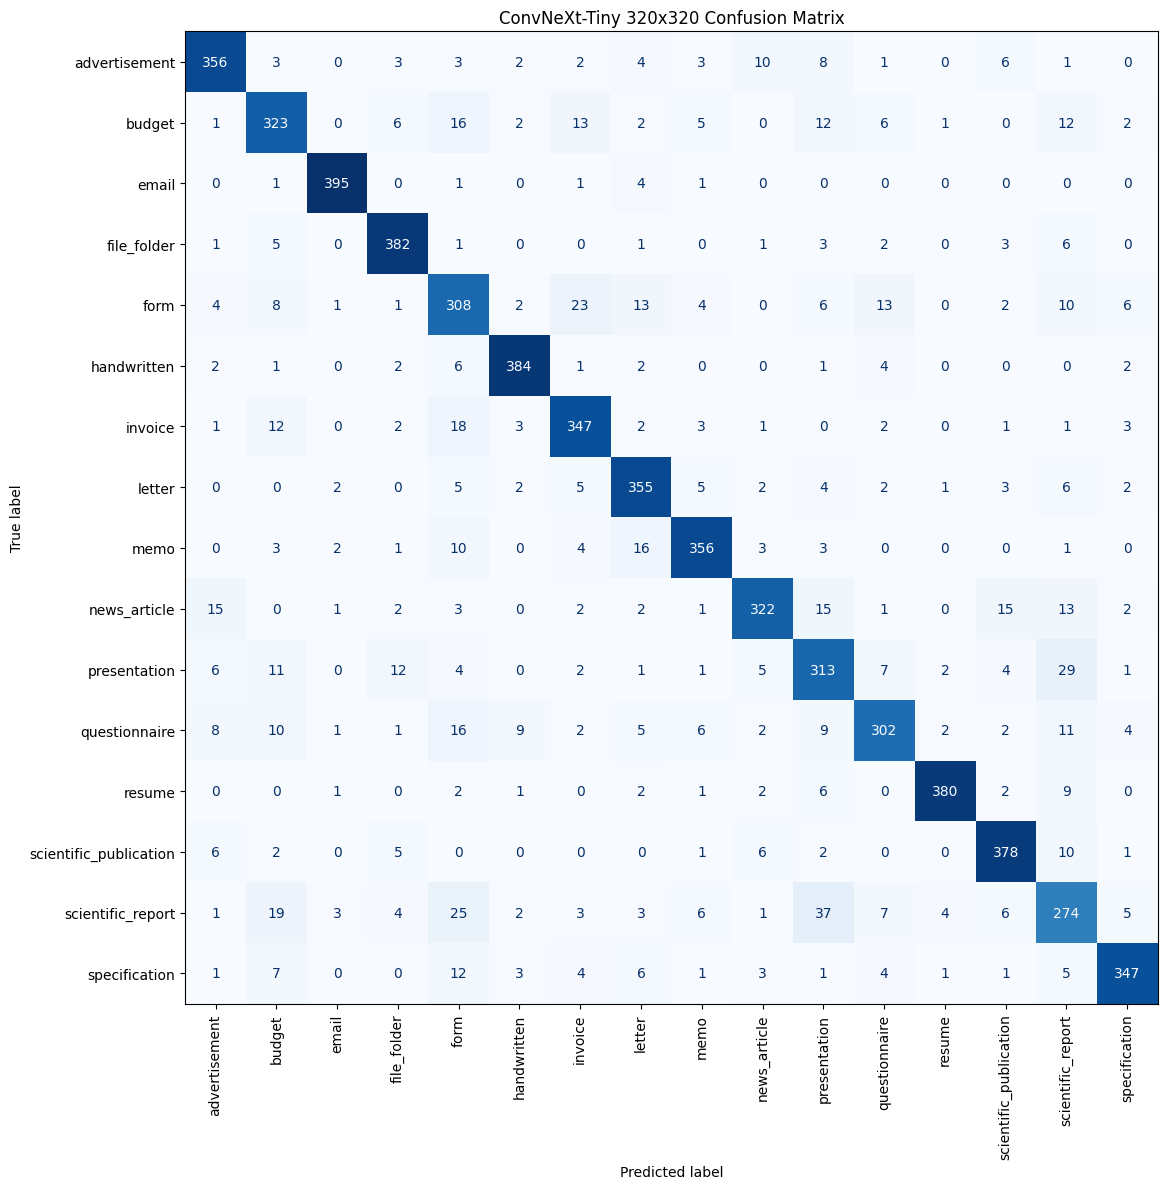


Evaluation files saved!

MODEL COMPARISON
              Model  Validation_Accuracy
EfficientNet-B0 224             0.832500
  ConvNeXt-Tiny 224             0.858616
  ConvNeXt-Tiny 320             0.862678


In [14]:
# Pastikan persiapan data sudah dijalankan
assert "val_data" in globals(), "Jalankan cell data splitting!"
assert "DocumentDataset" in globals(), "Jalankan cell dataset!"
assert "ResizeWithPadding" in globals(), "Jalankan cell preprocessing!"
assert "model_320" in globals(), "Jalankan checkpoint recovery!"

# Preprocessing sama dengan eksperimen resolusi 320
val_transform_320 = transforms.Compose([
    ResizeWithPadding(320),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

val_dataset_320 = DocumentDataset(
    val_data,
    val_transform_320
)

val_loader_320 = DataLoader(
    val_dataset_320,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Evaluasi checkpoint terbaik
model_320.eval()

y_true = []
y_pred = []

with torch.inference_mode():

    for images, labels in tqdm(
        val_loader_320,
        desc="Evaluating ConvNeXt 320"
    ):

        images = images.to(
            device, non_blocking=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model_320(images)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())

# Hitung metrik
accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro"
)

print("=" * 55)
print("CONVNEXT-TINY 320 FINAL EVALUATION")
print("=" * 55)

print(f"Validation Accuracy : {accuracy:.4%}")
print(f"Macro F1-Score      : {macro_f1:.4f}")
print("ConvNeXt 224        : 85.8616%")
print("EfficientNet B0     : 83.25%")

improvement = (accuracy * 100) - 85.8616

print(
    "Improvement vs 224 :",
    f"{improvement:+.2f} percentage points"
)

# Nama kelas berdasarkan metadata training
class_mapping = (
    train_df[["label", "class_name"]]
    .drop_duplicates()
    .sort_values("label")
)

class_names = class_mapping["class_name"].tolist()

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(16)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Simpan hasil evaluasi
EVAL_DIR_320 = Path(
    "/kaggle/working/convnext_320_evaluation"
)
EVAL_DIR_320.mkdir(parents=True, exist_ok=True)

report_df = pd.DataFrame(report).T

report_df.to_csv(
    EVAL_DIR_320 / "classification_report_320.csv"
)

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(16))
)

fig, ax = plt.subplots(figsize=(15, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False
)

plt.title("ConvNeXt-Tiny 320x320 Confusion Matrix")
plt.tight_layout()

plt.savefig(
    EVAL_DIR_320 / "confusion_matrix_320.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Ringkasan perbandingan model
comparison_df = pd.DataFrame({
    "Model": [
        "EfficientNet-B0 224",
        "ConvNeXt-Tiny 224",
        "ConvNeXt-Tiny 320"
    ],
    "Validation_Accuracy": [
        0.8325,
        0.858616,
        accuracy
    ]
})

comparison_df.to_csv(
    EVAL_DIR_320 / "model_comparison.csv",
    index=False
)

print("\nEvaluation files saved!")
print("\nMODEL COMPARISON")
print(comparison_df.to_string(index=False))